# Seven coarse-search methods, one fine stage: the whole flow, step by step

Same six parts as the teaching notebook (Header, Image Processing, Coarse Searching, Fine Matching, Result Thresholding, Evaluation), but every step calls the real functions in `src/` and runs on the NUDT thermal flights.

**The question.** The coarse search gives the fine stage 25 candidate places. Seven different coarse methods give seven different lists. Which list helps the fine stage find the true position most often?

| # | method | what it is |
|---|---|---|
| 1 | `edge_zncc` | baseline: edge-direction cells, masked ZNCC |
| 2 | `edge_cosine` | same cells, cosine score |
| 3 | `edge_mag` | total edge strength only (direction ignored) |
| 4 | `edge_zncc_w` | edge ZNCC after pre-whitening (flattens repeating city grids) |
| 5 | `mind_zncc` | MIND self-similarity cells (does not compare brightness between thermal and satellite) |
| 6 | `learned_zncc` | two small CNNs trained so the correlation peaks at the truth |
| 7 | `fused` | the best learned fusion of the six maps above (picked on NUDT valid) |

**What is reused, nothing is retrained.** The map store, the F4 weights (`results/overnight/models/f4.pt`), the fusion model and the saved geometry (`results/overnight/geometry.json`) come from the finished overnight run. Where to find any file: `index.md` in the base folder.

**Time.** Building the map store and the three feature families takes some minutes. After that every photo is quick. Lower `N_PHOTOS` for a first try.

---
# Part 1 · Header

**What it does:** sets up the tools, finds the NUDT data, defines how we are scored and picks the photos to test on.

**Input:** the NUDT test flights and the saved overnight results.

**Output:** `test_set` (photos, true positions, 5 km priors, sigmas, zoom levels), `camera`, the scoring rule.

## 1.1 Setup and settings

Everything is imported once, here. Functions of the pipeline come from the `src` package. The shared constants (`settings`) come from `header`, which is the same module the `src` code reads internally.

In [1]:
import os, sys, json, math, time, traceback
from pathlib import Path

import numpy as np
import pandas as pd
import cv2
import torch
import matplotlib.pyplot as plt
from matplotlib.colors import hsv_to_rgb
from IPython.display import display

ROOT = Path.cwd()
while not ((ROOT / "train").exists() and (ROOT / "src").exists()):
    ROOT = ROOT.parent                    # walk up to the repo folder
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "src"))
os.chdir(ROOT)

from header import settings
from train import config
from train.datasets import nudt_data
from train.features.edge import EdgeFamily
from train.features.mind import MindFamily
from train.features.learned_family import LearnedFamily
from train.maps.map_bank import compute_maps, z_stack

from src.header.satellite_map import SatelliteMap
from src.header.scoring import sigma_m, points_for_error, final_score
from src.evaluation.testset import TestSet
from src.evaluation.metrics import gated_curve
from src.image_processing.thermal import load_thermal_frame, normalise_frame
from src.image_processing.geometry import render_query
from src.image_processing.map_levels import level_gsd, level_for_height, map_piece
from src.image_processing.map_store import build_map_store
from src.image_processing.edge_features import query_edge_features
from src.coarse_search.search import correlation_maps, pick_peaks, cut_map_features
from src.coarse_search.fusion import load_model, fuse_maps
from src.fine_matching.matcher import load_matcher
from src.fine_matching.second_stage import prepare_canvas, check_candidate, second_stage
from src.result_thresholding.decision import final_answer, decide
from src.result_thresholding.pipeline import localise_photo

device = settings.DEVICE
print("running on:", device)

N_PHOTOS = 260       # test photos to run (spread over all flights)
SEED = 7
N_BOOT = 2000        # resamples for the confidence intervals
USE_FINE = True      # False = coarse search only

plt.rcParams["figure.dpi"] = 90
plt.rcParams["image.interpolation"] = "nearest"


def show(axis, picture, title="", cmap="gray", vmin=0, vmax=1):
    axis.imshow(picture, cmap=cmap, vmin=vmin, vmax=vmax)
    axis.set_title(title, fontsize=9)
    axis.set_xticks([])
    axis.set_yticks([])

running on: cuda


## 1.2 The data

NUDT Thermal-UAV: thermal photos of Changsha taken from 160 to 330 m, with GPS, height and heading, and a 0.3 m satellite map of the same city. `nudt_data.configure()` points the shared settings at this data set (photo folder, map levels 3 and 4, tilt correction off because pitch and roll are constant).

The overnight run also found two conventions by trial, saved in `geometry.json`: the sign of the heading and the scale between photo and map. We load them and apply them to the photos.

In [2]:
nudt_dir = nudt_data.configure()
camera = nudt_data.NudtCamera()

saved_geometry = json.load(open(config.OUT_DIR / "geometry.json"))
settings.GEOMETRY.update(saved_geometry["geometry"])
yaw_sign = saved_geometry["yaw_sign"]
print("geometry from the overnight run:", settings.GEOMETRY, "| yaw sign:", yaw_sign)

satellite_map = SatelliteMap(nudt_data.find_reference_map(nudt_dir))
print("map: %d x %d pixels, %.2f m per pixel" % (satellite_map.width, satellite_map.height, satellite_map.gsd))

all_items = nudt_data.read_split(nudt_dir, "test")
for item in all_items:
    item["yaw"] = yaw_sign * item["yaw_raw"]

chosen_ids = nudt_data.spread_sample(all_items, N_PHOTOS, SEED)
test_items = []
for index in chosen_ids:
    test_items.append(all_items[index])
flights = nudt_data.flight_labels(test_items)
test_set = TestSet(test_items, camera, satellite_map, flights, np.arange(len(test_items)))

heights = np.array([item["rel_height"] for item in test_items])
print("%d test photos from %d flights, height %.0f to %.0f m" % (len(test_items), len(set(flights)), heights.min(), heights.max()))
print("camera: focal length %.1f pixels, image %d x %d" % (camera.fx, camera.width, camera.height))

geometry from the overnight run: {'attitude': False, 'pitch_sign': -1, 'roll_sign': -1, 'yaw_offset': 0.0, 'scale': 0.8, 'height_offset': 0.0} | yaw sign: 1
map: 40961 x 27770 pixels, 0.30 m per pixel
260 test photos from 4 flights, height 207 to 329 m
camera: focal length 1562.6 pixels, image 1280 x 1024


## 1.3 How we are scored

For each photo the error is measured in units of sigma, the allowed error, which grows with the ground pixel size:

`GSD = height / focal length`, `sigma = sqrt(8^2 + (3 * GSD)^2)` metres.

Within 1 sigma earns +10, within 2 sigma +6, within 4 sigma +3, within 8 sigma 0, worse than that -20. A skipped photo earns 0. The final score is `60 * (total points / (10 * photos))`.

In [3]:
rows = []
for height in [160, 200, 250, 330]:
    rows.append({"height (m)": height, "GSD (m/px)": round(height / camera.fx, 3), "sigma (m)": round(sigma_m(height, camera.fx), 2)})
display(pd.DataFrame(rows))

errors_in_metres = np.arange(0, 100, 0.5)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for height, colour in [(160, "tab:blue"), (250, "tab:orange"), (330, "tab:red")]:
    points = []
    for error in errors_in_metres:
        points.append(points_for_error(error, height, camera.fx))
    axes[0].step(errors_in_metres, points, where="post", color=colour, label="%d m high (sigma %.1f m)" % (height, sigma_m(height, camera.fx)))
axes[0].set_xlabel("error (m)")
axes[0].set_ylabel("points")
axes[0].set_title("points for a given error: lower photos must be more exact")
axes[0].legend(fontsize=8)

axes[1].hist(heights, bins=20, color="gray")
axes[1].set_xlabel("height of the test photos (m)")
axes[1].set_title("the %d photos we test on" % len(heights))
plt.tight_layout()
plt.show()

,height (m),GSD (m/px),sigma (m)
0,160,0.102,8.01
1,200,0.128,8.01
2,250,0.160,8.01
3,330,0.211,8.03


KeyboardInterrupt: 

---
# Part 2 · Image Processing

**What it does:** turns one thermal photo into a north-up picture on the map grid (the canvas), prepares the satellite map once at two zoom levels, and describes both with edge cells.

**Input:** one photo with height and heading, and the satellite map.

**Output:** `canvas` and `valid` (which pixels are real photo), `store` (the map pictures and their cells), the cells of the query.

## 2.1 Zoom levels: how much ground does one photo cover?

`level_for_height` picks the map level whose 224 x 224 tile just contains the photo. Level 3 has 0.85 m pixels and level 4 has 1.2 m pixels. Higher photos need level 4.

,level,metres per pixel,tile covers (m)
0,3,0.849,190
1,4,1.200,269


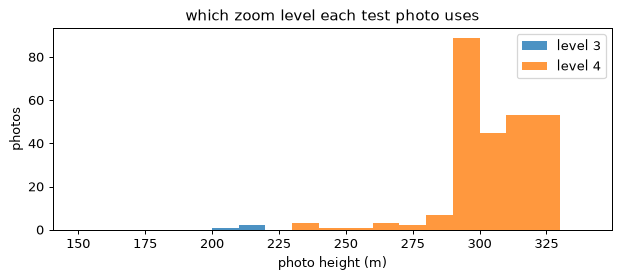

In [ ]:
rows = []
for level in settings.LEVELS:
    rows.append({"level": level, "metres per pixel": round(level_gsd(level), 3), "tile covers (m)": round(settings.TILE * level_gsd(level))})
display(pd.DataFrame(rows))

levels_of_photos = test_set.query_levels
fig, axis = plt.subplots(figsize=(7, 3.2))
for level, colour in [(3, "tab:blue"), (4, "tab:orange")]:
    axis.hist(heights[levels_of_photos == level], bins=np.arange(150, 345, 10), color=colour, alpha=0.8, label="level %d" % level)
axis.set_xlabel("photo height (m)")
axis.set_ylabel("photos")
axis.legend()
axis.set_title("which zoom level each test photo uses")
plt.tight_layout()
plt.show()

## 2.2 Cleaning up a thermal photo

The numbers of a thermal photo use only a small part of the 16-bit range, so the raw picture looks flat. `normalise_frame` stretches the range between the 1st and the 99th percentile and then applies local contrast (CLAHE). We show the lowest, a middle and the highest photo.

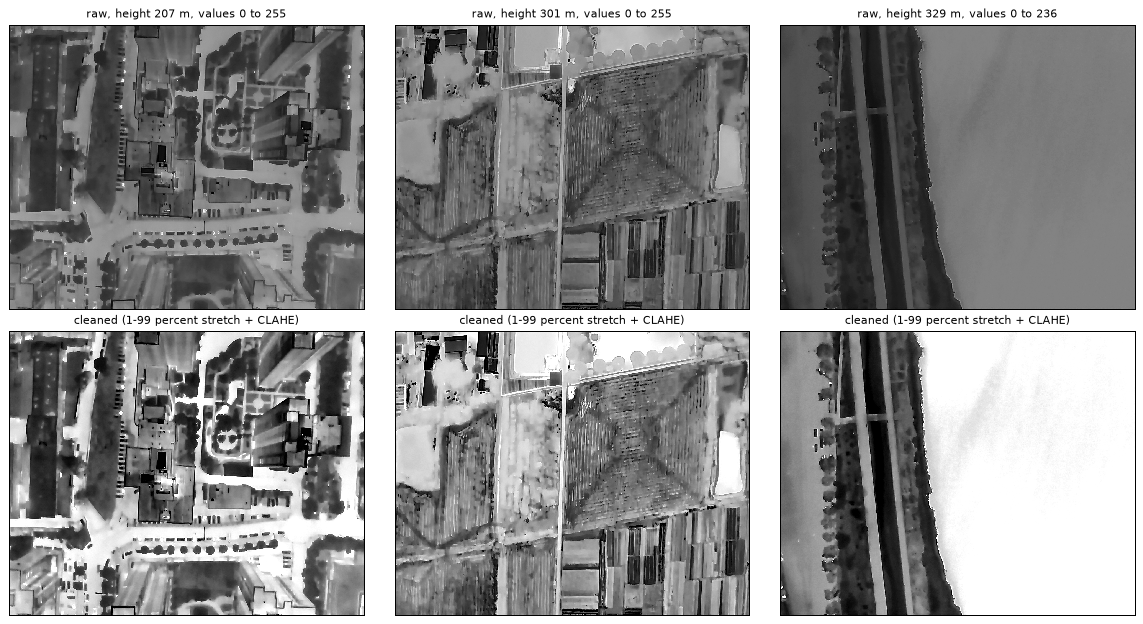

In [ ]:
order_by_height = np.argsort(heights)
example_photos = [int(order_by_height[0]), int(order_by_height[len(order_by_height) // 2]), int(order_by_height[-1])]

fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for column, photo in enumerate(example_photos):
    item = test_set.items[photo]
    raw = load_thermal_frame(item)
    cleaned = normalise_frame(raw)
    low, high = np.percentile(raw, [1, 99])
    show(axes[0, column], raw, "raw, height %.0f m, values %d to %d" % (item["rel_height"], raw.min(), raw.max()), vmin=raw.min(), vmax=raw.max())
    show(axes[1, column], cleaned, "cleaned (1-99 percent stretch + CLAHE)")
plt.tight_layout()
plt.show()

## 2.3 The map at two zoom levels (once, before any flight)

`build_map_store` shrinks the 0.3 m map to levels 3 and 4 and turns every level into edge cells. This is the slow step (minutes) and is done once. Left: level 4 with the photo positions, one 5 km search circle and the truth for that photo. Right: the same 190 m of ground at the two levels.

In [ ]:
store = build_map_store(satellite_map)
level_images = store["levels"]

level 3: 0.85 m/pixel, picture 14481 x 9818, map coverage 96%
level 4: 1.20 m/pixel, picture 10240 x 6942, map coverage 96%
map store ready, took 59 s


In [ ]:
example_photo = example_photos[1]
truth_x, truth_y = test_set.truths[example_photo]
prior_x, prior_y = test_set.priors[example_photo]

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [1.5, 1]})
overview = level_images[4]
gsd4 = level_gsd(4)
axes[0].imshow(overview, cmap="gray", extent=(0, overview.shape[1] * gsd4, overview.shape[0] * gsd4, 0))
axes[0].plot(test_set.truths[:, 0], test_set.truths[:, 1], ".", color="tab:red", markersize=3, label="test photo positions")
axes[0].add_patch(plt.Circle((prior_x, prior_y), settings.DISC_RADIUS, fill=False, color="deepskyblue", lw=2))
axes[0].plot(prior_x, prior_y, "o", color="deepskyblue", markersize=8, label="prior (the 5 km hint)")
axes[0].plot(truth_x, truth_y, "*", color="lime", markersize=15, markeredgecolor="black", label="truth")
axes[0].set_title("satellite map, level 4. The blue circle is what the system searches.")
axes[0].set_xlabel("metres east")
axes[0].set_ylabel("metres south")
axes[0].legend(fontsize=8, loc="lower right")

axes[1].axis("off")
for slot, level in enumerate([3, 4]):
    inset = axes[1].inset_axes([0.05, 0.52 - 0.5 * slot, 0.85, 0.46])
    piece = map_piece(level_images, level, truth_x, truth_y)
    show(inset, piece, "level %d: %.2f m per pixel, 224 x 224 pixels = %.0f m of ground" % (level, level_gsd(level), settings.TILE * level_gsd(level)))
plt.tight_layout()
plt.show()

## 2.4 Putting the photo on the map, north-up

`render_query(item, camera, level)` draws every pixel of a 224 x 224 north-up canvas by following its ray back into the photo (heading rotation, then scale), and returns the canvas and a mask of the pixels that really came from the photo. Below: the cleaned photo, the canvas, the mask, the true map tile and the photo laid at 50 percent over the map. If roads and field edges continue across the photo border, the geometry is right.

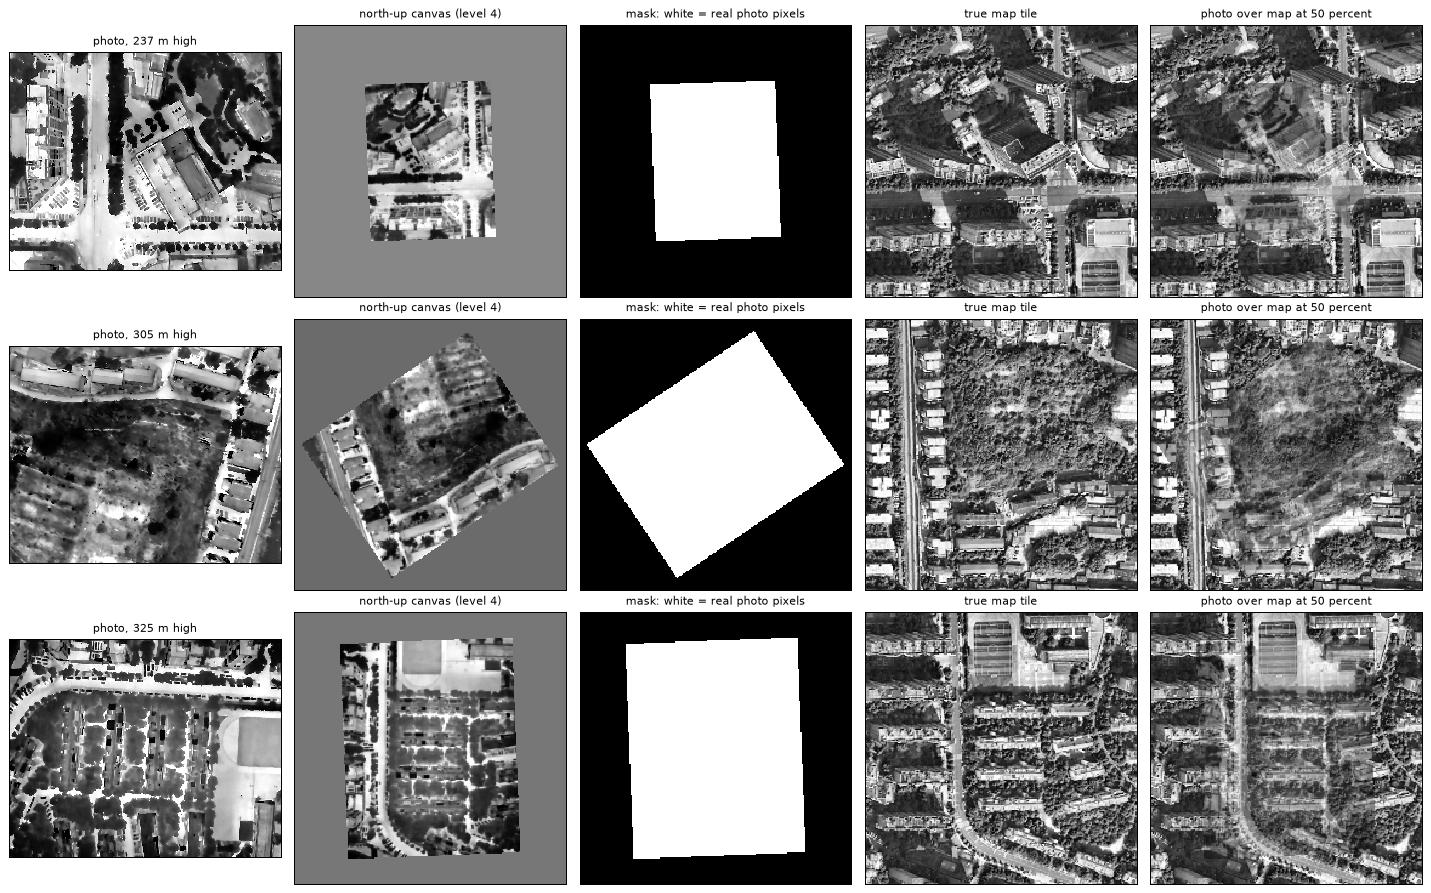

In [ ]:
fig, axes = plt.subplots(3, 5, figsize=(16, 10))
for row, photo in enumerate(example_photos):
    item = test_set.items[photo]
    level = int(test_set.query_levels[photo])
    canvas, valid = render_query(item, camera, level)
    true_tile = map_piece(level_images, level, test_set.truths[photo][0], test_set.truths[photo][1])
    blend = np.where(valid, 0.5 * true_tile + 0.5 * canvas, true_tile)
    show(axes[row, 0], normalise_frame(load_thermal_frame(item)), "photo, %.0f m high" % item["rel_height"])
    show(axes[row, 1], canvas, "north-up canvas (level %d)" % level)
    show(axes[row, 2], valid.astype(np.float32), "mask: white = real photo pixels")
    show(axes[row, 3], true_tile, "true map tile")
    show(axes[row, 4], blend, "photo over map at 50 percent")
plt.tight_layout()
plt.show()

## 2.5 Edge cells: what the matching really compares

A thermal photo and a satellite picture show the same place with different brightness. What they share is where the edges run. So each 4 x 4 pixel cell is described by 8 numbers: how much edge there is in each of 8 directions. `query_edge_features(canvas, valid)` gives 8 x 56 x 56 numbers for the query. The map goes through the same recipe once, in `build_map_store`.

Rows below: the picture, the edge strength per cell, and the dominant direction as colour (one hue per direction, brightness = strength). The query and the true map tile should look alike even though the grey pictures do not.

query cells: (8, 56, 56) | valid cells: 1202 of 3136


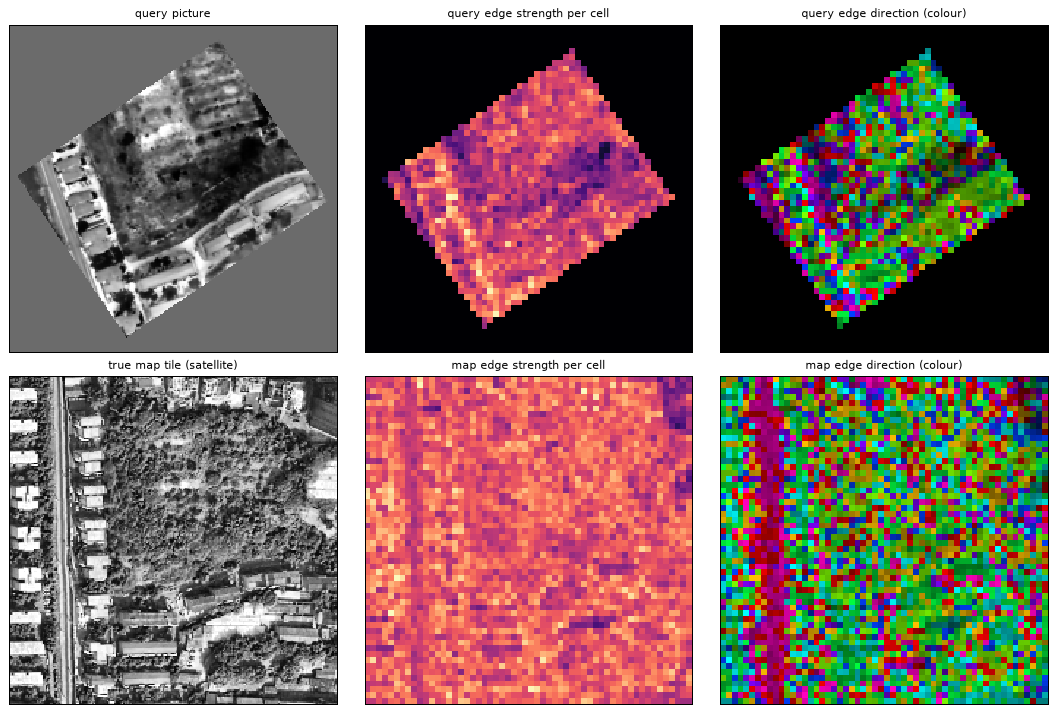

In [ ]:
def direction_colours(cells):
    strength = cells.sum(axis=0)
    dominant = cells.argmax(axis=0)
    hue = dominant / cells.shape[0]
    brightness = strength / (np.percentile(strength, 99) + 1e-6)
    brightness = np.clip(brightness, 0, 1)
    picture = np.stack([hue, np.ones_like(hue), brightness], axis=-1)
    return hsv_to_rgb(picture), strength


def map_cells_at(level, x_m, y_m, side_cells):
    gsd = level_gsd(level)
    top = int(round(y_m / gsd / settings.CELL - side_cells / 2))
    left = int(round(x_m / gsd / settings.CELL - side_cells / 2))
    return cut_map_features(store["features"][level], top, left, side_cells, side_cells)


photo = example_photos[1]
level = int(test_set.query_levels[photo])
canvas, valid = render_query(test_set.items[photo], camera, level)
query_cells, query_valid = query_edge_features(canvas, valid)
truth_x, truth_y = test_set.truths[photo]
true_tile = map_piece(level_images, level, truth_x, truth_y)
tile_cells = map_cells_at(level, truth_x, truth_y, query_cells.shape[1])
print("query cells:", query_cells.shape, "| valid cells: %d of %d" % (query_valid.sum(), query_valid.size))

query_colours, query_strength = direction_colours(query_cells)
tile_colours, tile_strength = direction_colours(tile_cells)
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
show(axes[0, 0], canvas, "query picture")
show(axes[0, 1], query_strength, "query edge strength per cell", cmap="magma", vmax=query_strength.max())
show(axes[0, 2], query_colours, "query edge direction (colour)")
show(axes[1, 0], true_tile, "true map tile (satellite)")
show(axes[1, 1], tile_strength, "map edge strength per cell", cmap="magma", vmax=tile_strength.max())
show(axes[1, 2], tile_colours, "map edge direction (colour)")
plt.tight_layout()
plt.show()

**Proof that brightness does not matter.** We make a negative of the query (dark becomes bright, like a thermal inversion) and compare its cells with the original's, cell by cell with the cosine similarity. Because the 8 directions describe lines and not which side is bright, the two should be almost identical. For comparison, the query against the true map tile, and against a tile from somewhere else.

In [ ]:
def mean_cell_similarity(cells_a, cells_b, valid_cells):
    total = 0.0
    count = 0
    for row in range(cells_a.shape[1]):
        for column in range(cells_a.shape[2]):
            if not valid_cells[row, column]:
                continue
            a = cells_a[:, row, column]
            b = cells_b[:, row, column]
            length = np.linalg.norm(a) * np.linalg.norm(b)
            if length > 0:
                total += float(a @ b) / length
                count += 1
    return total / max(count, 1)


negative = np.where(valid, 1.0 - canvas, canvas)
negative_cells, _ = query_edge_features(negative, valid)
elsewhere_cells = map_cells_at(level, truth_x + 1500, truth_y, query_cells.shape[1])

print("query against its own negative:  %.3f" % mean_cell_similarity(query_cells, negative_cells, query_valid))
print("query against the TRUE map tile: %.3f" % mean_cell_similarity(query_cells, tile_cells, query_valid))
print("query against a tile 1.5 km away: %.3f" % mean_cell_similarity(query_cells, elsewhere_cells, query_valid))

query against its own negative:  1.000
query against the TRUE map tile: 0.463
query against a tile 1.5 km away: 0.439


## 2.6 Three families of cells

The edge cells are one way to describe a picture. The overnight run added two more, built on the same 4 x 4 grid so the same fast correlation scores all of them:

- **MIND** (self-similarity): each pixel is described by how much its patch resembles the patches around it. It never compares brightness between thermal and satellite.
- **Learned**: two small CNNs (one for the photo, one for the map) trained so that the correlation of their cells peaks at the truth.

Below, the three families for the same photo and the same map place. Building the MIND and learned map cells takes a few minutes.

In [ ]:
start = time.time()
families = {"edge": EdgeFamily(store)}
families["mind"] = MindFamily(store, settings.LEVELS)
print("MIND cells ready, %.0f s" % (time.time() - start))

f4_file = config.OUT_DIR / "models" / "f4.pt"
base_names = list(config.MAP_NAMES_BASE)
if f4_file.exists():
    families["learned"] = LearnedFamily(store, settings.LEVELS, f4_file)
    base_names.append("learned_zncc")
    print("learned cells ready, %.0f s (hit rate %.2f vs %.2f for plain edges on held-out pairs)" % (
        time.time() - start, families["learned"].hit, families["learned"].baseline))
else:
    print("no f4.pt found: the learned method will be left out")

names = sorted(base_names, key=lambda name: (name != "edge_zncc", name))
print("score maps:", names)

MIND cells ready, 24 s
learned cells ready, 28 s (hit rate 0.93 vs 0.91 for plain edges on held-out pairs)
score maps: ['edge_zncc', 'edge_cosine', 'edge_mag', 'edge_zncc_w', 'learned_zncc', 'mind_zncc']


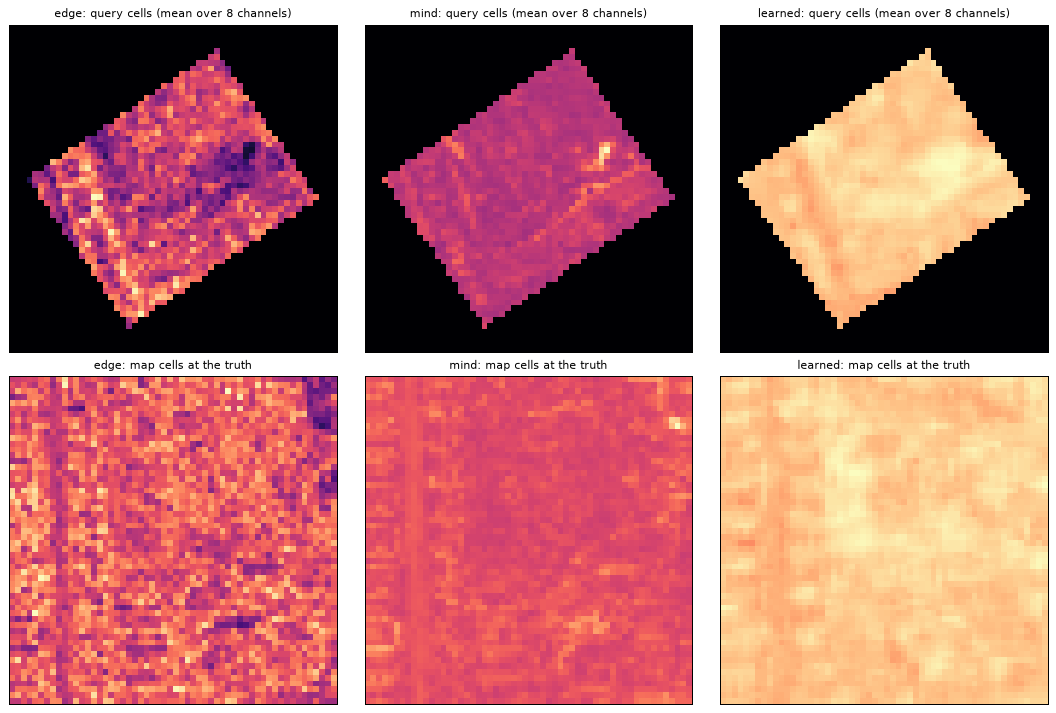

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for column, family_name in enumerate(["edge", "mind", "learned"]):
    if family_name not in families:
        continue
    family = families[family_name]
    query_family_cells, _ = family.query(canvas, valid)
    gsd = level_gsd(level)
    side = query_family_cells.shape[1]
    top = int(round(truth_y / gsd / settings.CELL - side / 2))
    left = int(round(truth_x / gsd / settings.CELL - side / 2))
    map_family_cells = cut_map_features(family.map_features(level), top, left, side, side)
    show(axes[0, column], np.abs(query_family_cells).mean(axis=0), "%s: query cells (mean over 8 channels)" % family_name, cmap="magma", vmax=np.abs(query_family_cells).mean(axis=0).max())
    show(axes[1, column], np.abs(map_family_cells).mean(axis=0), "%s: map cells at the truth" % family_name, cmap="magma", vmax=np.abs(map_family_cells).mean(axis=0).max())
plt.tight_layout()
plt.show()

---
# Part 3 · Coarse Searching: the seven methods

**What it does:** slides the photo's cells over every position inside the 5 km circle at once (FFT correlation) and turns each score map into the 25 best places.

**Input:** the cells of the canvas and the 5 km prior.

**Output:** per method, 25 candidates `[score, x, y, sharpness, ranking score]`.

All seven methods share the same window and the same grid, so the maps can be compared cell by cell. A method is just a different way of making ONE score map in (-1, 1) from the shared maps; `pick_peaks` (from `src`) then finds the 25 peaks with a blanked neighbourhood around each pick, so the next one is a different place.

## 3.1 Turning the shared maps into seven score maps

Methods 1 to 6 are single maps. Method 7 first turns every map into a robust z-score (median and spread over the circle), feeds them to the trained fusion model, and squashes the result with a sigmoid so it lives in (0, 1) like the others. Unusable positions (outside the circle or off the map) are -1.

In [ ]:
state = json.load(open(config.OUT_DIR / "state.json"))
best_fusion = state["results"]["fusion_best"]
fusion_file = config.OUT_DIR / "models" / "fusion" / (best_fusion["tag"] + ".pt")
fusion_model = load_model(fusion_file).to(device).eval()
fusion_columns = []
for map_name in best_fusion["subset"]:
    fusion_columns.append(names.index(map_name))
print("fusion model:", best_fusion["tag"], "| %s" % best_fusion["model_description"])

single_methods = ["edge_zncc", "edge_cosine", "edge_mag", "edge_zncc_w", "mind_zncc", "learned_zncc"]
METHODS = []
for method in single_methods:
    if method in names:
        METHODS.append(method)
METHODS.append("fused")
print(len(METHODS), "methods:", METHODS)


def make_one_score_map(method, maps, z, usable, context):
    if method == "fused":
        context_columns = []
        for column in fusion_columns:
            context_columns.append(2 * column)
            context_columns.append(2 * column + 1)
        context_columns.append(2 * len(names))
        fused = fuse_maps(fusion_model, z[..., fusion_columns], context[context_columns])
        return torch.where(usable, torch.sigmoid(fused / 10.0), torch.full_like(fused, -1.0))
    good = usable & (maps[method] > -1)
    return torch.where(good, maps[method], torch.full_like(maps[method], -1.0))


def make_score_maps(photo):
    item = test_set.items[photo]
    level = int(test_set.query_levels[photo])
    canvas, valid = render_query(item, camera, level)
    maps, geometry = compute_maps(canvas, valid, level, test_set.priors[photo], families, names)
    z, usable, context = z_stack(maps, geometry, names)
    scores = {}
    for method in METHODS:
        scores[method] = make_one_score_map(method, maps, z, usable, context)
    return canvas, valid, level, geometry, scores


def errors_in_sigma(peaks, photo):
    truth = test_set.truths[photo]
    errors = []
    for row in peaks:
        if row[1] < 1e8:
            errors.append(math.hypot(row[1] - truth[0], row[2] - truth[1]) / test_set.sigmas[photo])
    if len(errors) == 0:
        errors.append(1e9)
    return errors

fusion model: edge_zncc+edge_cosine+edge_mag+edge_zncc_w+mind_zncc+learned_zncc__monotone | 90 parameters
7 methods: ['edge_zncc', 'edge_cosine', 'edge_mag', 'edge_zncc_w', 'mind_zncc', 'learned_zncc', 'fused']


## 3.2 One photo, seven heat maps

Each panel is one method's score over the 5 km circle (hidden outside it). Green star: the truth. Blue circle: the search area. Cyan squares: the first five peaks, numbered. The title gives the error of peak 1 in sigma and the smallest error among all 25 peaks (the best the fine stage could possibly reach).

photo 9 | city1_300_ortho_day | height 305 m | level 4 | sigma 8.0 m


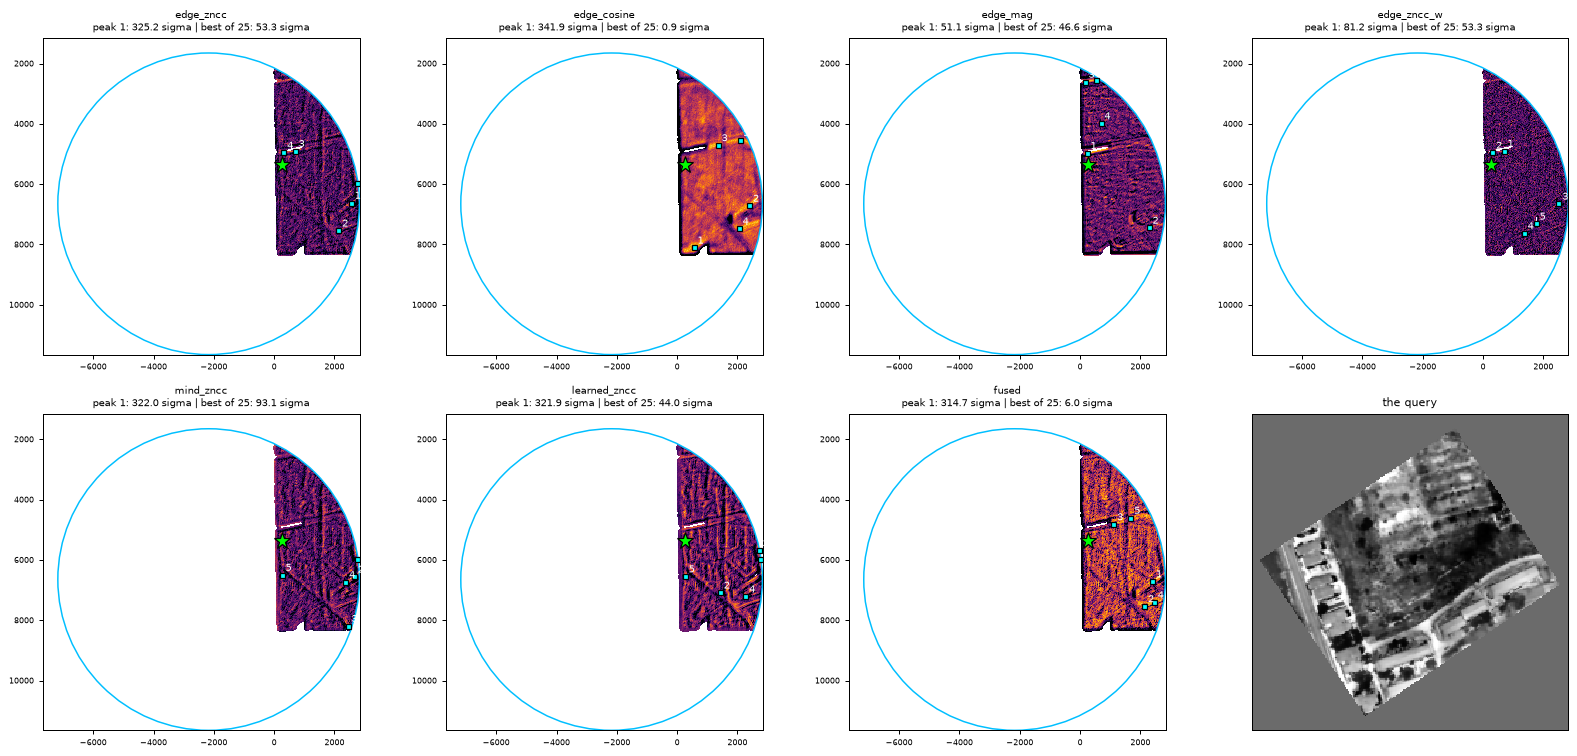

In [ ]:
def draw_heat_map(axis, score_map, geometry, photo, peaks, title):
    heat = score_map.cpu().numpy().copy()
    inside = geometry["inside"].cpu().numpy()
    heat[~inside | (heat <= -1)] = np.nan
    x_m = geometry["x_m"].cpu().numpy()
    y_m = geometry["y_m"].cpu().numpy()
    low = np.nanpercentile(heat, 5)
    axis.imshow(heat, cmap="inferno", vmin=low, vmax=np.nanmax(heat), extent=(x_m[0], x_m[-1], y_m[-1], y_m[0]))
    axis.add_patch(plt.Circle(test_set.priors[photo], settings.DISC_RADIUS, fill=False, color="deepskyblue", lw=1.2))
    axis.plot(*test_set.truths[photo], "*", color="lime", markersize=14, markeredgecolor="black")
    for rank in range(5):
        if peaks[rank, 1] < 1e8:
            axis.plot(peaks[rank, 1], peaks[rank, 2], "s", color="cyan", markersize=4, markeredgecolor="black")
            axis.annotate(str(rank + 1), (peaks[rank, 1], peaks[rank, 2]), color="white", fontsize=8, xytext=(3, 3), textcoords="offset points")
    axis.set_title(title, fontsize=8)
    axis.tick_params(labelsize=6)


photo = example_photos[1]
canvas, valid, level, geometry, scores = make_score_maps(photo)
print("photo %d | %s | height %.0f m | level %d | sigma %.1f m" % (
    photo, test_set.items[photo]["flight"], test_set.items[photo]["rel_height"], level, test_set.sigmas[photo]))

fig, axes = plt.subplots(2, 4, figsize=(18, 8.5))
axes = axes.ravel()
example_peaks = {}
for slot, method in enumerate(METHODS):
    peaks = pick_peaks(scores[method], geometry)
    example_peaks[method] = peaks
    errors = errors_in_sigma(peaks, photo)
    draw_heat_map(axes[slot], scores[method], geometry, photo, peaks, "%s\npeak 1: %.1f sigma | best of 25: %.1f sigma" % (method, errors[0], min(errors)))
show(axes[len(METHODS)], canvas, "the query")
for slot in range(len(METHODS) + 1, 8):
    axes[slot].axis("off")
plt.tight_layout()
plt.show()

**Check against the original code.** `src.coarse_search.search.correlation_maps` is the original edge-only search. Method 1 must give the very same ZNCC map. If this prints a tiny number, the overnight map bank and the pipeline agree.

In [ ]:
query_cells, query_valid = query_edge_features(canvas, valid)
original_maps, original_geometry = correlation_maps(store["features"], level, query_cells, query_valid, test_set.priors[photo])
usable_now = original_geometry["inside"] & (original_maps["zncc"] > -1)
difference = (original_maps["zncc"] - scores["edge_zncc"]).abs()[usable_now].max().item()
print("largest difference between src correlation_maps and method 1 (edge_zncc): %.2e" % difference)

largest difference between src correlation_maps and method 1 (edge_zncc): 0.00e+00


## 3.3 What is under the peaks

For two methods, the map tile under each of the first five peaks with the query laid over it. A green frame means the peak is within 4 sigma of the truth, red means not. The bars show the score of all 25 peaks: one tall bar means the method is sure, many similar bars mean look-alikes.

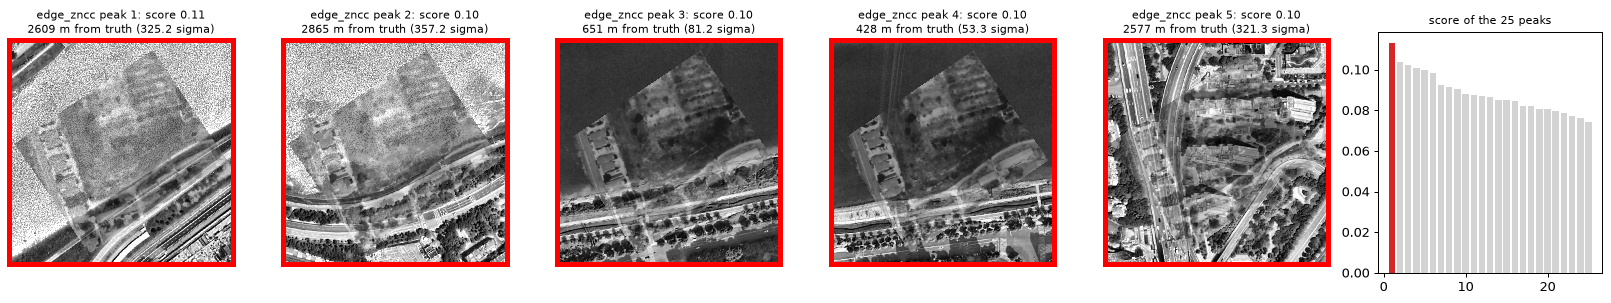

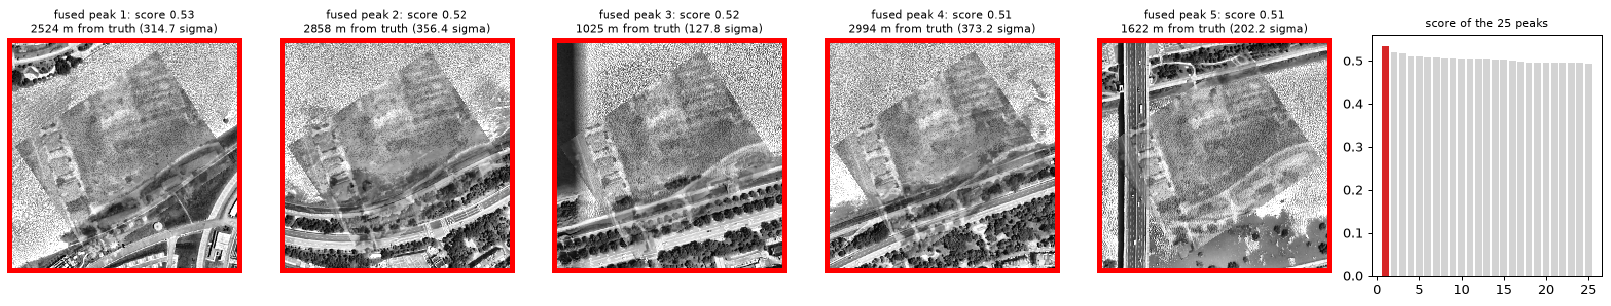

In [ ]:
def show_peak_tiles(method):
    peaks = example_peaks[method]
    fig, axes = plt.subplots(1, 6, figsize=(18, 3.4))
    for rank in range(5):
        x_m, y_m = peaks[rank, 1], peaks[rank, 2]
        tile = map_piece(level_images, level, x_m, y_m)
        blend = np.where(valid, 0.5 * tile + 0.5 * canvas, tile)
        distance = math.hypot(x_m - test_set.truths[photo][0], y_m - test_set.truths[photo][1])
        show(axes[rank], blend, "%s peak %d: score %.2f\n%.0f m from truth (%.1f sigma)" % (method, rank + 1, peaks[rank, 0], distance, distance / test_set.sigmas[photo]))
        if distance / test_set.sigmas[photo] <= 4:
            frame_colour = "lime"
        else:
            frame_colour = "red"
        for side in axes[rank].spines.values():
            side.set_edgecolor(frame_colour)
            side.set_linewidth(4)
    axes[5].bar(range(1, len(peaks) + 1), peaks[:, 0], color=["tab:red"] + ["lightgray"] * (len(peaks) - 1))
    axes[5].set_title("score of the 25 peaks", fontsize=9)
    plt.tight_layout()
    plt.show()


show_peak_tiles("edge_zncc")
show_peak_tiles("fused")

## 3.4 Run the coarse search on the whole sample

For every sample photo and every method we keep the 25 peaks (the fine stage needs them). A photo that fails in the shared step is reported and skipped for all methods, so every method sees exactly the same photos.

Reading the table: `top-1 within k sigma` is the share of photos whose first peak is that close to the truth. `best of 25 within 4 sigma` is the ceiling: how often the right place is in the list at all, which is all the fine stage can use.

In [ ]:
coarse_peaks = {}
failed_photos = []
start = time.time()
for count in range(len(test_set.items)):
    try:
        canvas_now, valid_now, level_now, geometry_now, scores_now = make_score_maps(count)
        peaks_now = {}
        for method in METHODS:
            peaks_now[method] = pick_peaks(scores_now[method], geometry_now)
    except Exception as error:
        print("photo %d failed: %s: %s" % (count, type(error).__name__, str(error)[:120]))
        if len(failed_photos) == 0:
            print(traceback.format_exc())
        failed_photos.append(count)
        continue
    for method in METHODS:
        coarse_peaks[(count, method)] = peaks_now[method]
    if device == "cuda":
        torch.cuda.empty_cache()
    if count % 10 == 0:
        print("coarse search: photo %d of %d, %.0f s" % (count + 1, len(test_set.items), time.time() - start))

photos_done = []
for count in range(len(test_set.items)):
    if count not in failed_photos:
        photos_done.append(count)
print("coarse search done for %d photos (%d failed), %.0f s" % (len(photos_done), len(failed_photos), time.time() - start))

coarse search: photo 1 of 60, 1 s
coarse search: photo 11 of 60, 10 s
coarse search: photo 21 of 60, 20 s
coarse search: photo 31 of 60, 29 s
coarse search: photo 41 of 60, 38 s
coarse search: photo 51 of 60, 48 s
coarse search done for 60 photos (0 failed), 56 s


,top-1 within 1 sigma,top-1 within 2 sigma,top-1 within 4 sigma,best of 25 within 4 sigma,median top-1 error (sigma)
method,,,,,
edge_zncc,0.750,0.750,0.750,0.833,0.519
edge_cosine,0.700,0.700,0.700,0.883,0.568
edge_mag,0.217,0.217,0.217,0.467,304.701
edge_zncc_w,0.683,0.683,0.683,0.783,0.541
mind_zncc,0.667,0.683,0.683,0.800,0.609
learned_zncc,0.700,0.767,0.783,0.900,0.596
fused,0.783,0.800,0.800,0.883,0.519


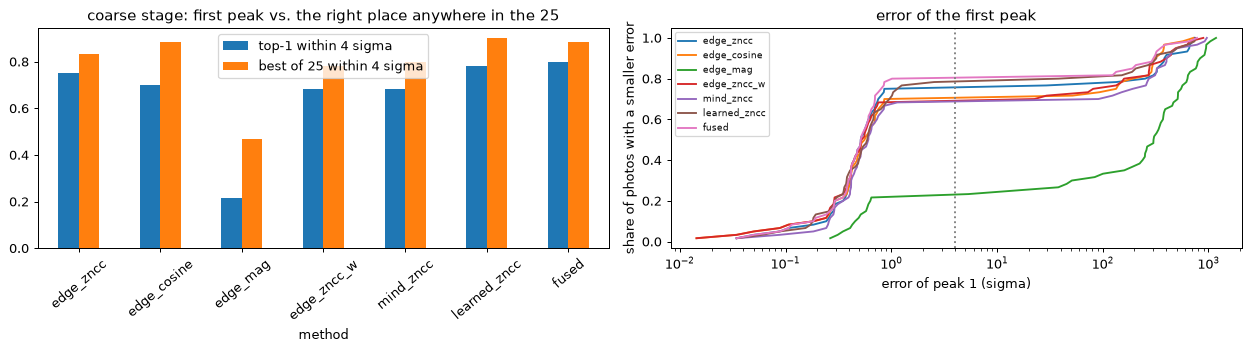

In [ ]:
rows = []
coarse_top1 = {}
coarse_best25 = {}
for method in METHODS:
    top1_list = []
    best_list = []
    for photo in photos_done:
        errors = errors_in_sigma(coarse_peaks[(photo, method)], photo)
        top1_list.append(errors[0])
        best_list.append(min(errors))
    coarse_top1[method] = np.array(top1_list)
    coarse_best25[method] = np.array(best_list)
    rows.append({"method": method,
                 "top-1 within 1 sigma": (coarse_top1[method] <= 1).mean(),
                 "top-1 within 2 sigma": (coarse_top1[method] <= 2).mean(),
                 "top-1 within 4 sigma": (coarse_top1[method] <= 4).mean(),
                 "best of 25 within 4 sigma": (coarse_best25[method] <= 4).mean(),
                 "median top-1 error (sigma)": np.median(coarse_top1[method])})
coarse_table = pd.DataFrame(rows).set_index("method")
display(coarse_table.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
coarse_table[["top-1 within 4 sigma", "best of 25 within 4 sigma"]].plot.bar(ax=axes[0], rot=40)
axes[0].set_title("coarse stage: first peak vs. the right place anywhere in the 25")
for method in METHODS:
    sorted_errors = np.sort(coarse_top1[method])
    axes[1].plot(sorted_errors, np.arange(1, len(sorted_errors) + 1) / len(sorted_errors), label=method)
axes[1].set_xscale("log")
axes[1].set_xlabel("error of peak 1 (sigma)")
axes[1].set_ylabel("share of photos with a smaller error")
axes[1].axvline(4, color="gray", ls=":")
axes[1].legend(fontsize=7)
axes[1].set_title("error of the first peak")
plt.tight_layout()
plt.show()

---
# Part 4 · Fine Matching

**What it does:** looks at each of the 25 places with a proper image matcher: SuperPoint keypoints, LightGlue matching with the MINIMA weights (made for different picture types), and RANSAC. It counts how many matched points agree on one common shift (the inliers).

**Input:** the canvas and the 25 candidates of one method.

**Output:** per candidate the number of inliers and a small position correction (`shift`, in metres).

A true place has many agreeing points. A look-alike has few. The fine stage is identical for all seven methods.

## 4.1 Load the matcher

The weights sit next to the NUDT data, so we point `settings.MINIMA_FILE` there before loading (the default path does not exist and the loader would try to download them).

In [ ]:
matcher = None
if USE_FINE:
    settings.MINIMA_FILE = nudt_dir / "checkpoint" / "MINIMA" / "minima_lightglue.pth"
    if settings.MINIMA_FILE.exists():
        matcher = load_matcher()
    else:
        print("MINIMA weights not found at", settings.MINIMA_FILE, "-> the fine stage is skipped")
        USE_FINE = False

MINIMA weights loaded. File layers not in model: 0 | model layers not in file: 1
  missing (should be none or only harmless buffers): ['confidence_thresholds']


## 4.2 The matcher at work

The same photo against (left) the map at the true position and (right) a look-alike: the strongest wrong peak of method 1, or a place 1 km away if there is none. Green lines are matched pairs that agree with the common shift (inliers), thin red lines do not. `check_candidate` also cuts the map tile at the candidate for us.

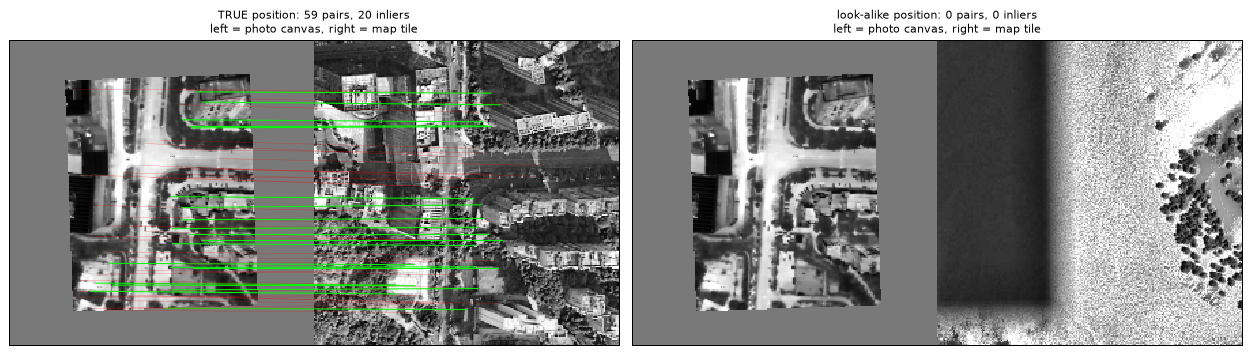

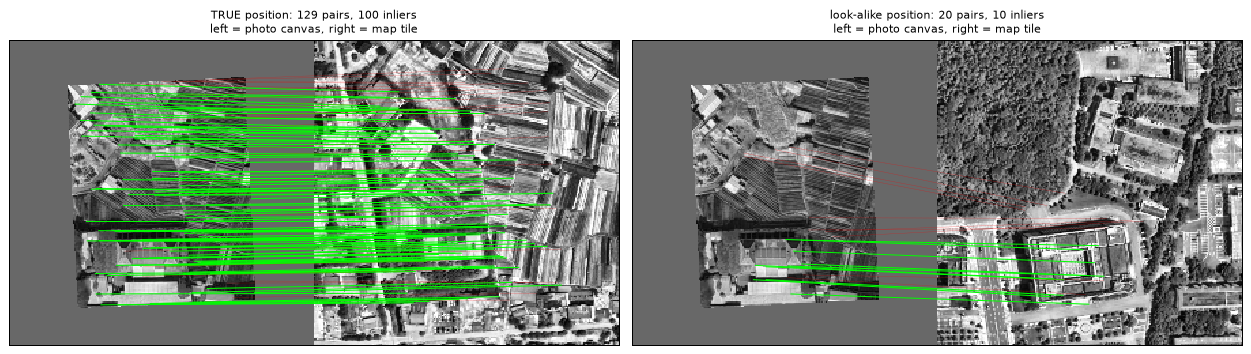

In [ ]:
def draw_matches(axis, canvas_picture, tile, result, title):
    both = np.concatenate([canvas_picture, tile], axis=1)
    axis.imshow(both, cmap="gray", vmin=0, vmax=1)
    width = canvas_picture.shape[1]
    for pair in range(len(result["points_a"])):
        x_a, y_a = result["points_a"][pair]
        x_b, y_b = result["points_b"][pair]
        if result["inliers"][pair]:
            axis.plot([x_a, x_b + width], [y_a, y_b], color="lime", lw=0.8)
        else:
            axis.plot([x_a, x_b + width], [y_a, y_b], color="red", lw=0.3, alpha=0.5)
    axis.set_title(title, fontsize=9)
    axis.set_xticks([])
    axis.set_yticks([])


def show_matcher_example(photo):
    level = int(test_set.query_levels[photo])
    canvas, valid = render_query(test_set.items[photo], camera, level)
    canvas_features = prepare_canvas(matcher, canvas, valid)
    padded = np.where(valid, canvas, canvas[valid].mean())
    truth = test_set.truths[photo]
    wrong = (truth[0] + 1000, truth[1])
    peaks = coarse_peaks[(photo, "edge_zncc")]
    for rank in range(len(peaks)):
        if peaks[rank, 1] < 1e8 and math.hypot(peaks[rank, 1] - truth[0], peaks[rank, 2] - truth[1]) > 4 * test_set.sigmas[photo]:
            wrong = (peaks[rank, 1], peaks[rank, 2])
            break
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
    for axis, (name, position) in zip(axes, [("TRUE position", truth), ("look-alike position", wrong)]):
        result = check_candidate(matcher, canvas_features, level_images, level, position[0], position[1])
        draw_matches(axis, padded, result["tile"], result, "%s: %d pairs, %d inliers\nleft = photo canvas, right = map tile" % (name, result["n_pairs"], result["n_inliers"]))
    plt.tight_layout()
    plt.show()


if matcher is not None:
    for photo in [photos_done[len(photos_done) // 4], photos_done[(3 * len(photos_done)) // 4]]:
        show_matcher_example(photo)

## 4.3 Check the 25 candidates of every method, for every photo

`second_stage(matcher, canvas, valid, level, peaks, level_images)` runs `check_candidate` on all 25 candidates and returns the inlier count and the shift of each. A shift larger than the allowed range makes the candidate count as 0 inliers, because a wild correction means the fit is not trusted. Seven methods times 25 candidates per photo: this is the slow loop.

In [ ]:
stage_two = {}
start = time.time()
if matcher is not None:
    for position, photo in enumerate(photos_done):
        level = int(test_set.query_levels[photo])
        canvas, valid = render_query(test_set.items[photo], camera, level)
        for method in METHODS:
            peaks = coarse_peaks[(photo, method)]
            stage_two[(photo, method)] = second_stage(matcher, canvas, valid, level, peaks, level_images)
        if device == "cuda":
            torch.cuda.empty_cache()
        if position % 5 == 0:
            print("fine stage: photo %d of %d, %.0f s" % (position + 1, len(photos_done), time.time() - start))
    print("fine stage done, %.0f s (%.1f s per photo for all %d methods)" % (time.time() - start, (time.time() - start) / len(photos_done), len(METHODS)))

fine stage: photo 1 of 60, 5 s
fine stage: photo 6 of 60, 31 s
fine stage: photo 11 of 60, 57 s
fine stage: photo 16 of 60, 93 s
fine stage: photo 21 of 60, 138 s
fine stage: photo 26 of 60, 163 s
fine stage: photo 31 of 60, 189 s
fine stage: photo 36 of 60, 214 s
fine stage: photo 41 of 60, 240 s
fine stage: photo 46 of 60, 265 s
fine stage: photo 51 of 60, 290 s
fine stage: photo 56 of 60, 313 s
fine stage done, 334 s (5.6 s per photo for all 7 methods)


**Where do the inliers sit?** For each method, the mean inlier count of the candidate at each coarse rank (1 = the coarse search's favourite). If the true places were mostly at rank 1, the curve would fall steeply. A flat curve means the matcher has to do the real work of choosing.

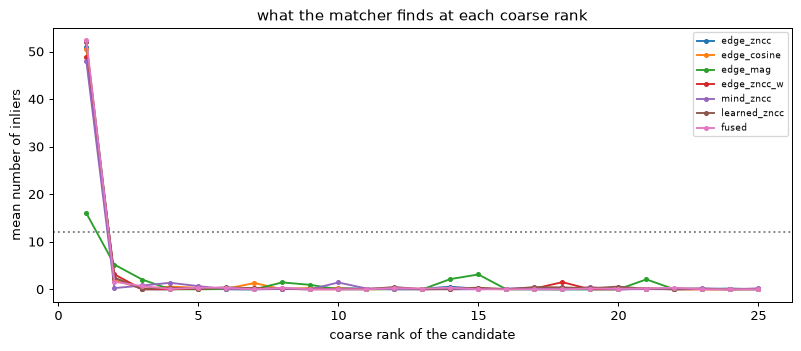

In [ ]:
if matcher is not None:
    fig, axis = plt.subplots(figsize=(9, 4))
    for method in METHODS:
        mean_inliers = np.zeros(settings.NUM_PEAKS)
        for photo in photos_done:
            mean_inliers += stage_two[(photo, method)]["inliers"]
        mean_inliers = mean_inliers / len(photos_done)
        axis.plot(range(1, settings.NUM_PEAKS + 1), mean_inliers, marker="o", markersize=3, label=method)
    axis.axhline(settings.MIN_INLIERS, color="gray", ls=":")
    axis.set_xlabel("coarse rank of the candidate")
    axis.set_ylabel("mean number of inliers")
    axis.legend(fontsize=7)
    axis.set_title("what the matcher finds at each coarse rank")
    plt.tight_layout()
    plt.show()

---
# Part 5 · Result Thresholding

**What it does:** chooses the answer among the 25 candidates and decides whether to give it or to say "no match".

**Input:** the candidates and their inlier counts and shifts.

**Output:** one position per photo, the inliers behind it and an answer-or-skip flag.

`final_answer(peaks, stage2)` takes the candidate with the most inliers (ties go to the better coarse score) and adds its shift. If even the best has fewer than `MIN_INLIERS` (12) inliers, the matcher was not convincing and it keeps the coarse search's own first peak. `decide(inliers)` answers only when the chosen candidate has at least 12 inliers. A wrong answer costs -20 and a right one earns at most +10, so answering only pays when we are more than two-thirds sure.

## 5.1 One photo, seven answers

For the example photo: what each method's coarse first peak was worth, which candidate the fine stage chose, and what it did to the error.

In [ ]:
answers = {}
if matcher is not None:
    for photo in photos_done:
        for method in METHODS:
            peaks = coarse_peaks[(photo, method)]
            x, y, inliers, chosen = final_answer(peaks, stage_two[(photo, method)])
            truth = test_set.truths[photo]
            error_m = math.hypot(x - truth[0], y - truth[1])
            answers[(photo, method)] = dict(x=float(x), y=float(y), inliers=int(inliers), chosen=int(chosen), answered=decide(inliers),
                                            error_m=error_m, error_sigma=error_m / test_set.sigmas[photo])

    photo = photos_done[len(photos_done) // 2]
    rows = []
    for method in METHODS:
        answer = answers[(photo, method)]
        rows.append({"method": method, "coarse peak 1 error (sigma)": round(errors_in_sigma(coarse_peaks[(photo, method)], photo)[0], 2),
                     "chosen candidate": answer["chosen"] + 1, "inliers": answer["inliers"], "answer?": answer["answered"],
                     "final error (sigma)": round(answer["error_sigma"], 2),
                     "points": points_for_error(answer["error_m"], test_set.items[photo]["rel_height"], camera.fx)})
    print("photo", photo, "| height %.0f m | sigma %.1f m" % (test_set.items[photo]["rel_height"], test_set.sigmas[photo]))
    display(pd.DataFrame(rows).set_index("method"))

photo 30 | height 307 m | sigma 8.0 m


,coarse peak 1 error (sigma),chosen candidate,inliers,answer?,final error (sigma),points
method,,,,,,
edge_zncc,0.59,1,8,False,0.59,10
edge_cosine,297.12,1,8,False,297.12,-20
edge_mag,0.59,1,8,False,0.59,10
edge_zncc_w,0.59,1,8,False,0.59,10
mind_zncc,0.59,1,8,False,0.59,10
learned_zncc,0.59,1,8,False,0.59,10
fused,0.59,1,8,False,0.59,10


## 5.2 One photo at a time: the whole chain as one function

In the flight, photos arrive one by one and each is answered alone. `localise_photo(item, prior, camera, store, matcher)` is that whole chain for the original edge-only search (coarse, fine, decision). It must give the same answer as method 1 here, because method 1 is the same search. A small difference can appear from the random numbers of RANSAC; the first peaks of the coarse search should match exactly.

In [ ]:
if matcher is not None:
    check_photos = [photos_done[0], photos_done[len(photos_done) // 2], photos_done[-1]]
    for photo in check_photos:
        result = localise_photo(test_set.items[photo], test_set.priors[photo], camera, store, matcher)
        mine = answers[(photo, "edge_zncc")]
        same_peak = abs(result["peaks"][0, 1] - coarse_peaks[(photo, "edge_zncc")][0, 1]) < 1.0
        error_m = math.hypot(result["x"] - test_set.truths[photo][0], result["y"] - test_set.truths[photo][1])
        print("photo %3d: first coarse peak identical: %s | localise_photo error %.0f m, %d inliers | notebook error %.0f m, %d inliers | %.1f s" % (
            photo, same_peak, error_m, result["inliers"], mine["error_m"], mine["inliers"], result["seconds"]))

photo   0: first coarse peak identical: True | localise_photo error 5 m, 56 inliers | notebook error 5 m, 56 inliers | 0.9 s
photo  30: first coarse peak identical: True | localise_photo error 5 m, 8 inliers | notebook error 5 m, 8 inliers | 1.0 s
photo  59: first coarse peak identical: True | localise_photo error 3 m, 54 inliers | notebook error 3 m, 54 inliers | 1.0 s


---
# Part 6 · Evaluation

**What it does:** judges the seven methods. This is the only part that reads the true positions.

**Input:** the answers of all methods on all sample photos.

**Output:** tables and pictures: accuracy at 1, 2 and 4 sigma, the contest score, a paired comparison with the baseline, what the fine stage did with each list of candidates, and examples.

## 6.1 Results table

- **coarse** columns: the first peak of the coarse search alone, and the ceiling (right place anywhere in the 25).
- **fine** columns: the final answer after fine matching and the decision rule.
- **final score (/60)**: the contest score. A photo whose inliers are below 12 is not answered and counts 0 points; an answered photo counts its points (+10 to -20).
- **points vs edge_zncc**: the average points per photo minus those of method 1, with a 95 percent interval from a paired bootstrap (the same photos are resampled for both methods). If the interval includes 0, the difference could be luck.

In [ ]:
def build_result_rows():
    rows = []
    for photo in photos_done:
        item = test_set.items[photo]
        for method in METHODS:
            row = dict(photo=photo, method=method, height=item["rel_height"], low_flight=bool(test_set.city[photo]),
                       coarse_top1_sigma=errors_in_sigma(coarse_peaks[(photo, method)], photo)[0],
                       coarse_best25_sigma=min(errors_in_sigma(coarse_peaks[(photo, method)], photo)))
            if matcher is not None:
                answer = answers[(photo, method)]
                points = points_for_error(answer["error_m"], item["rel_height"], camera.fx)
                row.update(fine_x=answer["x"], fine_y=answer["y"], fine_error_m=answer["error_m"], fine_sigma=answer["error_sigma"],
                           inliers=answer["inliers"], chosen=answer["chosen"], answered=answer["answered"],
                           points_if_answered=points)
                if answer["answered"]:
                    row["points"] = points
                else:
                    row["points"] = 0
            rows.append(row)
    return pd.DataFrame(rows)


def paired_bootstrap_mean(values_a, values_b, resamples, seed):
    generator = np.random.default_rng(seed)
    differences = np.asarray(values_a, dtype=float) - np.asarray(values_b, dtype=float)
    means = []
    for _ in range(resamples):
        picks = generator.integers(0, len(differences), len(differences))
        means.append(differences[picks].mean())
    return float(differences.mean()), float(np.quantile(means, 0.025)), float(np.quantile(means, 0.975))


results = build_result_rows()
results.to_csv(config.OUT_DIR / "seven_methods_per_photo.csv", index=False)

baseline = results[results.method == "edge_zncc"].set_index("photo")
rows = []
for method in METHODS:
    mine = results[results.method == method].set_index("photo").loc[baseline.index]
    row = {"method": method, "photos": len(mine),
           "coarse top-1 <= 4 sigma": (mine.coarse_top1_sigma <= 4).mean(),
           "coarse best of 25 <= 4 sigma": (mine.coarse_best25_sigma <= 4).mean()}
    if matcher is not None:
        difference, low, high = paired_bootstrap_mean(mine.points, baseline.points, N_BOOT, SEED)
        row.update({"fine <= 1 sigma": (mine.fine_sigma <= 1).mean(), "fine <= 2 sigma": (mine.fine_sigma <= 2).mean(),
                    "fine <= 4 sigma": (mine.fine_sigma <= 4).mean(), "median fine error (m)": mine.fine_error_m.median(),
                    "answered": mine.answered.mean(), "mean inliers": mine.inliers.mean(),
                    "final score (/60)": final_score(list(mine.points)),
                    "points vs edge_zncc": difference, "95% low": low, "95% high": high})
    rows.append(row)
summary = pd.DataFrame(rows).set_index("method")
summary.to_csv(config.OUT_DIR / "seven_methods_summary.csv")
display(summary.round(3))

,photos,coarse top-1 <= 4 sigma,coarse best of 25 <= 4 sigma,fine <= 1 sigma,fine <= 2 sigma,fine <= 4 sigma,median fine error (m),answered,mean inliers,final score (/60),points vs edge_zncc,95% low,95% high
method,,,,,,,,,,,,,
edge_zncc,60,0.750,0.833,0.800,0.800,0.800,3.827,0.750,54.167,42.0,0.000,0.000,0.000
edge_cosine,60,0.700,0.883,0.800,0.800,0.800,3.623,0.750,54.533,42.0,0.000,-0.500,0.500
edge_mag,60,0.217,0.467,0.417,0.417,0.417,542.032,0.400,33.017,24.0,-3.000,-4.333,-1.500
edge_zncc_w,60,0.683,0.783,0.767,0.767,0.767,3.827,0.733,54.250,41.0,-0.167,-0.500,0.000
mind_zncc,60,0.683,0.800,0.750,0.783,0.783,3.943,0.700,52.283,41.6,-0.067,-0.900,0.933
learned_zncc,60,0.783,0.900,0.783,0.817,0.833,3.335,0.783,55.033,40.6,-0.233,-1.534,1.000
fused,60,0.800,0.883,0.817,0.833,0.833,3.545,0.783,54.967,40.6,-0.233,-1.167,0.467


## 6.2 Coarse against fine

Left: the share within 4 sigma of the coarse first peak, of the ceiling (right place somewhere in the 25) and of the final answer. The distance from ceiling to final is what the fine stage failed to use; the distance from first peak to final is what it gained. Right: the final score of each method.

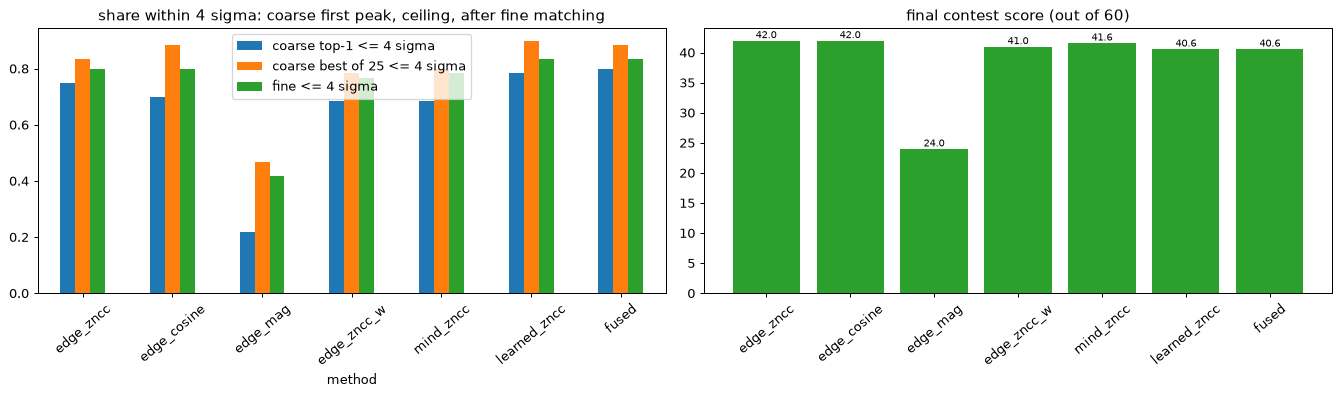

In [ ]:
if matcher is not None:
    fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
    summary[["coarse top-1 <= 4 sigma", "coarse best of 25 <= 4 sigma", "fine <= 4 sigma"]].plot.bar(ax=axes[0], rot=40)
    axes[0].set_title("share within 4 sigma: coarse first peak, ceiling, after fine matching")
    scores_to_plot = summary["final score (/60)"]
    axes[1].bar(range(len(METHODS)), scores_to_plot, color="tab:green")
    axes[1].set_xticks(range(len(METHODS)))
    axes[1].set_xticklabels(METHODS, rotation=40)
    axes[1].set_title("final contest score (out of 60)")
    for position, value in enumerate(scores_to_plot):
        axes[1].text(position, value, "%.1f" % value, ha="center", va="bottom", fontsize=8)
    plt.tight_layout()
    plt.show()

## 6.3 What the fine stage did to each list

Per method, three counts over the sample photos:

- *had it in the 25 but lost it*: the right place was among the candidates, yet the final answer is further than 4 sigma. The matcher (or the inlier rule) missed it.
- *rescued*: the coarse first peak was wrong, the fine stage still ended within 4 sigma. This is the benefit of listing 25 places.
- *broke it*: the coarse first peak was right and the final answer is not.

,had it in the 25 but lost it,"rescued (peak 1 wrong, final right)","broke it (peak 1 right, final wrong)",right place not in the 25 at all
method,,,,
edge_zncc,2,3,0,10
edge_cosine,5,6,0,7
edge_mag,3,12,0,32
edge_zncc_w,1,5,0,13
mind_zncc,1,6,0,12
learned_zncc,4,3,0,6
fused,3,2,0,7


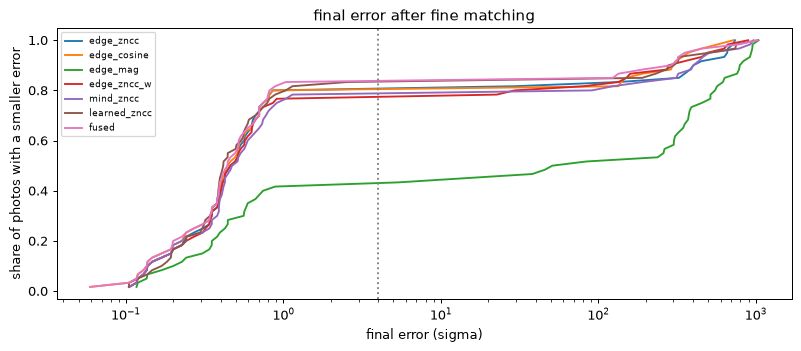

In [ ]:
if matcher is not None:
    rows = []
    for method in METHODS:
        mine = results[results.method == method]
        rows.append({"method": method,
                     "had it in the 25 but lost it": int(((mine.coarse_best25_sigma <= 4) & (mine.fine_sigma > 4)).sum()),
                     "rescued (peak 1 wrong, final right)": int(((mine.coarse_top1_sigma > 4) & (mine.fine_sigma <= 4)).sum()),
                     "broke it (peak 1 right, final wrong)": int(((mine.coarse_top1_sigma <= 4) & (mine.fine_sigma > 4)).sum()),
                     "right place not in the 25 at all": int((mine.coarse_best25_sigma > 4).sum())})
    display(pd.DataFrame(rows).set_index("method"))

    fig, axis = plt.subplots(figsize=(9, 4))
    for method in METHODS:
        sorted_errors = np.sort(results[results.method == method].fine_sigma.values)
        axis.plot(sorted_errors, np.arange(1, len(sorted_errors) + 1) / len(sorted_errors), label=method)
    axis.set_xscale("log")
    axis.axvline(4, color="gray", ls=":")
    axis.set_xlabel("final error (sigma)")
    axis.set_ylabel("share of photos with a smaller error")
    axis.legend(fontsize=7)
    axis.set_title("final error after fine matching")
    plt.tight_layout()
    plt.show()

## 6.4 Answer only when sure

So far every photo whose inliers reach 12 is answered. Here the cut-off moves: for each method we answer only the photos whose inlier count is at least a threshold and score the rest 0. `gated_curve` (from `src.evaluation.metrics`) gives the contest score against the share of photos answered. This reads thresholds off the same photos, so the curves are optimistic; they show the shape, not a promise.

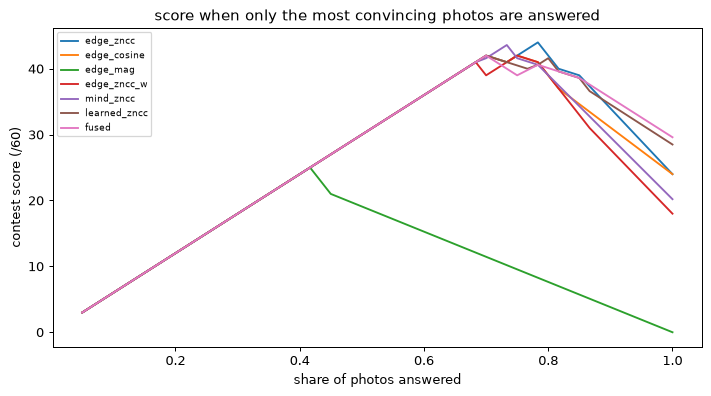

In [ ]:
if matcher is not None:
    fig, axis = plt.subplots(figsize=(8, 4.5))
    for method in METHODS:
        mine = results[results.method == method].sort_values("photo")
        shares, gated_scores = gated_curve(mine.inliers.values.astype(float), mine.points_if_answered.values)
        axis.plot(shares, gated_scores, label=method)
    axis.set_xlabel("share of photos answered")
    axis.set_ylabel("contest score (/60)")
    axis.legend(fontsize=7)
    axis.set_title("score when only the most convincing photos are answered")
    plt.tight_layout()
    plt.show()

## 6.5 Low photos against high photos

Photos from 200 m or lower see little ground with fine detail; higher photos see more but with larger pixels, and the allowed error sigma is larger. The final score per method in each group.

In [ ]:
if matcher is not None:
    rows = []
    for method in METHODS:
        mine = results[results.method == method]
        low = mine[mine.low_flight]
        high = mine[~mine.low_flight]
        row = {"method": method, "low photos": len(low), "high photos": len(high)}
        if len(low) > 0:
            row["score low (/60)"] = final_score(list(low.points))
            row["fine <= 4 sigma low"] = (low.fine_sigma <= 4).mean()
        if len(high) > 0:
            row["score high (/60)"] = final_score(list(high.points))
            row["fine <= 4 sigma high"] = (high.fine_sigma <= 4).mean()
        rows.append(row)
    display(pd.DataFrame(rows).set_index("method").round(3))

,low photos,high photos,score high (/60),fine <= 4 sigma high
method,,,,
edge_zncc,0,60,42.0,0.800
edge_cosine,0,60,42.0,0.800
edge_mag,0,60,24.0,0.417
edge_zncc_w,0,60,41.0,0.767
mind_zncc,0,60,41.6,0.783
learned_zncc,0,60,40.6,0.833
fused,0,60,40.6,0.833


## 6.6 Good and bad cases, side by side

A photo that method 7 (fused) got right and method 1 (the baseline) got wrong, and the opposite if there is one. Columns: the query, the map at the baseline's answer, the map at the fused answer, the map at the truth (each with the query laid over it). A good answer looks like the truth column.

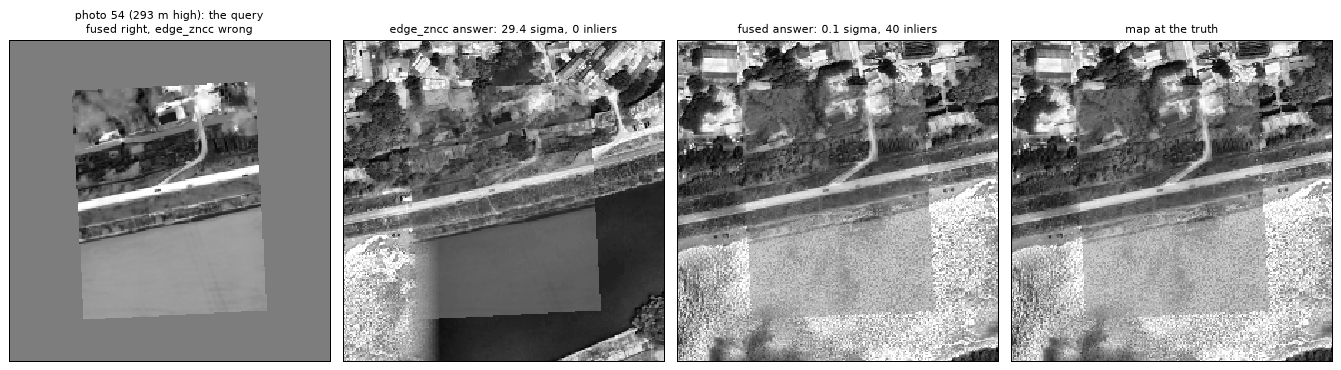

In [ ]:
def blend_at(photo, x_m, y_m):
    level = int(test_set.query_levels[photo])
    canvas, valid = render_query(test_set.items[photo], camera, level)
    tile = map_piece(level_images, level, x_m, y_m)
    return np.where(valid, 0.5 * tile + 0.5 * canvas, tile), canvas


def pick_cases(winner, loser):
    cases = []
    for photo in photos_done:
        win = results[(results.photo == photo) & (results.method == winner)].iloc[0]
        lose = results[(results.photo == photo) & (results.method == loser)].iloc[0]
        if win.fine_sigma <= 1 and lose.fine_sigma > 4:
            cases.append(photo)
    return cases


if matcher is not None:
    cases = []
    for photo in pick_cases("fused", "edge_zncc")[:2]:
        cases.append((photo, "fused right, edge_zncc wrong"))
    for photo in pick_cases("edge_zncc", "fused")[:1]:
        cases.append((photo, "edge_zncc right, fused wrong"))
    if len(cases) == 0:
        print("no photo where one of the two methods is within 1 sigma and the other beyond 4 sigma in this sample")
    for photo, label in cases:
        base = results[(results.photo == photo) & (results.method == "edge_zncc")].iloc[0]
        fused = results[(results.photo == photo) & (results.method == "fused")].iloc[0]
        truth = test_set.truths[photo]
        fig, axes = plt.subplots(1, 4, figsize=(15, 4))
        blend_base, canvas_now = blend_at(photo, base.fine_x, base.fine_y)
        blend_fused, _ = blend_at(photo, fused.fine_x, fused.fine_y)
        blend_truth, _ = blend_at(photo, truth[0], truth[1])
        show(axes[0], canvas_now, "photo %d (%.0f m high): the query\n%s" % (photo, test_set.items[photo]["rel_height"], label))
        show(axes[1], blend_base, "edge_zncc answer: %.1f sigma, %d inliers" % (base.fine_sigma, base.inliers))
        show(axes[2], blend_fused, "fused answer: %.1f sigma, %d inliers" % (fused.fine_sigma, fused.inliers))
        show(axes[3], blend_truth, "map at the truth")
        plt.tight_layout()
        plt.show()

## 6.7 Summary

The final table once more, sorted by the contest score, with how each method compares to the baseline. Per-photo rows are saved in `results/overnight/seven_methods_per_photo.csv` and the table in `results/overnight/seven_methods_summary.csv`.

**Caveats that go with every number above.**
1. This is a sample of `N_PHOTOS` photos from the NUDT test flights, thermal against one city's map. With few photos the intervals are wide; read the `95% low / high` columns before believing a difference.
2. The geometry (heading sign, scale 0.8) was fitted on a few training photos by the overnight run, not known. A wrong convention hurts every method alike.
3. The fusion model and the learned features were trained on NUDT train photos. A gain here says nothing yet about another city or camera; the `official` stage of `run_overnight.py` is the check for that.
4. The prior is simulated: a random point up to 5 km from the truth (`TestSet.priors`).

In [ ]:
if matcher is not None:
    ordered = summary.sort_values("final score (/60)", ascending=False)
    display(ordered[["final score (/60)", "fine <= 4 sigma", "coarse best of 25 <= 4 sigma", "answered", "points vs edge_zncc", "95% low", "95% high"]].round(3))
else:
    display(coarse_table.round(3))

,final score (/60),fine <= 4 sigma,coarse best of 25 <= 4 sigma,answered,points vs edge_zncc,95% low,95% high
method,,,,,,,
edge_zncc,42.0,0.800,0.833,0.750,0.000,0.000,0.000
edge_cosine,42.0,0.800,0.883,0.750,0.000,-0.500,0.500
mind_zncc,41.6,0.783,0.800,0.700,-0.067,-0.900,0.933
edge_zncc_w,41.0,0.767,0.783,0.733,-0.167,-0.500,0.000
learned_zncc,40.6,0.833,0.900,0.783,-0.233,-1.534,1.000
fused,40.6,0.833,0.883,0.783,-0.233,-1.167,0.467
edge_mag,24.0,0.417,0.467,0.400,-3.000,-4.333,-1.500
